In [1]:
from random import shuffle, seed
from tensorflow import keras
import tensorflow as tf
import pandas as pd
import numpy as np
from pathlib import Path
import hashlib
import kagglehub


Charger les images

In [2]:

project_dir = Path.cwd().parent
dataset_dir = project_dir / "data" / "mri-for-brain-tumor-with-bounding-boxes"


if not dataset_dir.is_dir():
    print("the data is downloading")
    path = kagglehub.dataset_download(
    "ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes",
    output_dir=str(dataset_dir) )
else:
    print("data already downloaded")



data already downloaded


Charger les images et préparer les ensembles de données.

In [3]:
train_ds = keras.utils.image_dataset_from_directory(
    dataset_dir / "Train",
    image_size = (224, 224),
    batch_size=32,
    shuffle=True,
    seed=42
)

class_names = train_ds.class_names

val_ds = keras.utils.image_dataset_from_directory(
    dataset_dir / "Val",
    class_names = class_names,
    image_size = (224, 224),
    batch_size= None,
    shuffle=True,
    seed=42
)

val_ds, test_ds = keras.utils.split_dataset(
    val_ds,
    left_size=0.6,
    shuffle=True,
    seed=42
)

val_ds = val_ds.batch(32).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.batch(32).prefetch(tf.data.AUTOTUNE)

Found 4737 files belonging to 4 classes.
Found 512 files belonging to 4 classes.


Explorer les classes et afficher un exemple par classe.

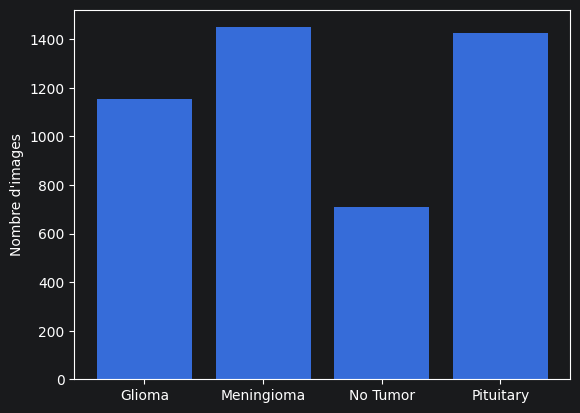

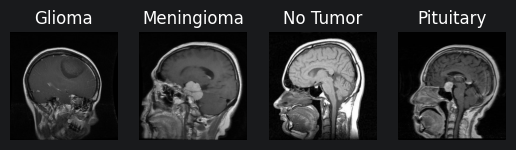

In [4]:
import matplotlib.pyplot as plt

# Compter les images par classe.
class_images = [
    list((dataset_dir / "Train" / name).rglob("*.jpg"))
    for name in class_names
]

plt.bar(class_names, [len(images) for images in class_images])
plt.ylabel("Nombre d'images")
plt.show()

# Afficher une image par classe.
for i, name in enumerate(class_names):
    plt.subplot(1, len(class_names), i + 1)
    plt.imshow(keras.utils.load_img(class_images[i][0]))
    plt.title(name)
    plt.axis("off")
plt.show()


Appliquer le retournement, la rotation, la translation, le zoom, le flou et le bruit uniquement aux images d'entraînement. Ces transformations ne changent pas le nombre d'images par classe.

In [5]:
@keras.utils.register_keras_serializable()
class TrainingBlur(keras.layers.AveragePooling2D):
    def call(self, inputs, training=None):
        if training:
            return super().call(inputs)
        return inputs


augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(factor=0.02),
    keras.layers.RandomTranslation(height_factor=0.03, width_factor=0.03),
    keras.layers.RandomZoom(0.05),
    TrainingBlur(pool_size=3, strides=1, padding="same"),
    keras.layers.Rescaling(1/255),
    keras.layers.GaussianNoise(stddev=3 / 255),
    keras.layers.ReLU(max_value=1),
], name="augmentation")

normalization = keras.layers.Rescaling(1/127.5, offset=-1)





Charger le modèle préentraîné GoogLeNet (InceptionV3), geler ses couches de base, remplacer sa tête de classification par une nouvelle adaptée au nombre de classes du dataset, puis entraîner uniquement cette dernière pour effectuer le Feature Extraction.

In [6]:
base_model = keras.applications.InceptionV3(
    weights="imagenet"  ,
    include_top = False ,
    input_shape = (224, 224, 3),
)
base_model.trainable = False
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    augmentation,
    normalization,
    base_model,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(len(class_names), activation="softmax")
])

In [7]:
model.compile(
    optimizer = keras.optimizers.Adam(learning_rate = 0.001),
    metrics = ["accuracy"],
    loss =  "sparse_categorical_crossentropy"
)

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor= "val_loss",
        patience = 3,
        restore_best_weights= True
    ),
    keras.callbacks.ModelCheckpoint(
        "best_model.keras",
        monitor = "val_loss",
        save_best_only = True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor = "val_loss",
        factor= 0.5,
        patience =2
    ),
    keras.callbacks.TensorBoard(
        log_dir="logs/classification/run_01",
        histogram_freq=0
    )
]

training

In [ ]:
history = model.fit(
    train_ds,
    validation_data = val_ds,
    epochs=10,
    callbacks = callbacks
)